# ¿Quién abandona el banco y a quién retener primero?

Proyecto FENIX · Semanas 1, 2 y 3 | Exploración, estadística descriptiva e inferencia | Dataset: 10,000 clientes de un banco en Francia, Alemania y España

**El problema.** Un banco con 10,000 clientes en Francia, Alemania y España está perdiendo clientes. El equipo de retención no puede llamar a todos, así que necesita saber a quién contactar primero.

**Los datos.** El dataset «Churn Modelling» de Kaggle describe a cada cliente por su perfil (edad, género, país), su situación financiera (puntaje crediticio, saldo, salario estimado) y su relación con el banco (antigüedad, número de productos, tarjeta de crédito y actividad). La variable objetivo, `Exited`, vale **1** si el cliente abandonó el banco y **0** si permaneció.

**Pregunta de estas semanas:** ¿qué perfiles de clientes presentan mayor tasa de abandono?

**Qué hace este notebook**

| Parte | Pregunta | Lo que usamos (visto en clase) |
|---|---|---|
| 1 · Datos (semanas 1 y 2) | ¿Qué tenemos y está limpio? | `read_csv`, `drop`, `isna`, `duplicated`, `info` |
| 2 · Semana 2: Análisis exploratorio | ¿Cómo son los clientes que se van? | `describe`, `value_counts`, media y mediana, `groupby`, `crosstab`, boxplot y gráficas de barras |
| 3 · Semana 3: Probabilidad e inferencia | ¿Las diferencias son reales o pueden ser azar? | Proporciones, intervalo de confianza al 95%, prueba chi-cuadrada |
| 4 · Conclusiones | ¿Qué perfiles abandonan más? | Lo que aprendimos de las tres semanas |

> **Alcance:** exploración, estadística descriptiva, probabilidad e inferencia básica. No entrenamos modelos predictivos (eso empieza en la semana 7) ni afirmamos causas del abandono.

## 1. Datos | Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
try:
    from google.colab import files
    import os
    if not os.path.exists("Churn_Modelling.csv"):
        files.upload()
except ImportError:
    pass

df = pd.read_csv("Churn_Modelling.csv")
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print(df.shape)
print("Columnas para el análisis:", list(df.columns))
df.head()

(10000, 11)
Columnas para el análisis: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**Qué vemos:** 10,000 clientes y 11 columnas. Quitamos `RowNumber`, `CustomerId` y `Surname` porque solo identifican el registro; no describen el comportamiento del cliente.

### 1.1 Calidad de datos
Antes de analizar, comprobamos si hay valores faltantes o filas duplicadas.

In [3]:
print("Valores faltantes:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
df.info()

Valores faltantes: 0
Filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB


**Qué vemos:** ningún dato vacío y ninguna fila duplicada. Las columnas `Geography` y `Gender` son texto; las demás son números. Los datos se pueden usar tal como están.

## 2 · Semana 2: Análisis exploratorio
**Pregunta:** ¿cómo son los clientes que se van?

### 2.1 Variables numéricas

In [4]:
df[["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]].describe().round(2)

,CreditScore,Age,Tenure,Balance,EstimatedSalary
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,650.53,38.92,5.01,76485.89,100090.24
std,96.65,10.49,2.89,62397.41,57510.49
min,350.00,18.00,0.00,0.00,11.58
25%,584.00,32.00,3.00,0.00,51002.11
50%,652.00,37.00,5.00,97198.54,100193.92
75%,718.00,44.00,7.00,127644.24,149388.25
max,850.00,92.00,10.00,250898.09,199992.48


**Qué vemos:**
- La edad va de 18 a 92 años, con media de 39.
- En `Balance`, el cuartil 25% es 0: eso indica que **al menos** una cuarta parte de los clientes tiene saldo cero. Contándolos, son **3,617 clientes (36%)** con saldo **exactamente 0**, mientras que la mediana es de 97 mil. Hay un grupo grande de clientes sin dinero depositado.
- El salario estimado se reparte de forma pareja: media y mediana casi iguales (100 mil).

### 2.2 ¿Qué porcentaje de clientes abandonó el banco?
Como `Exited` solo toma los valores 0 y 1, su media equivale a la proporción de abandonos.

In [5]:
print("Clientes que permanecieron / abandonaron:")
print(df["Exited"].value_counts().sort_index())
print(f"Tasa de abandono: {df['Exited'].mean():.1%}")

Clientes que permanecieron / abandonaron:
Exited
0    7963
1    2037
Name: count, dtype: int64
Tasa de abandono: 20.4%


**Qué vemos:** 2,037 de 10,000 clientes abandonaron: el **20.4%**. De cada 10 clientes, 2 se van.

### 2.3 Clientes que se quedan y que abandonan, por país

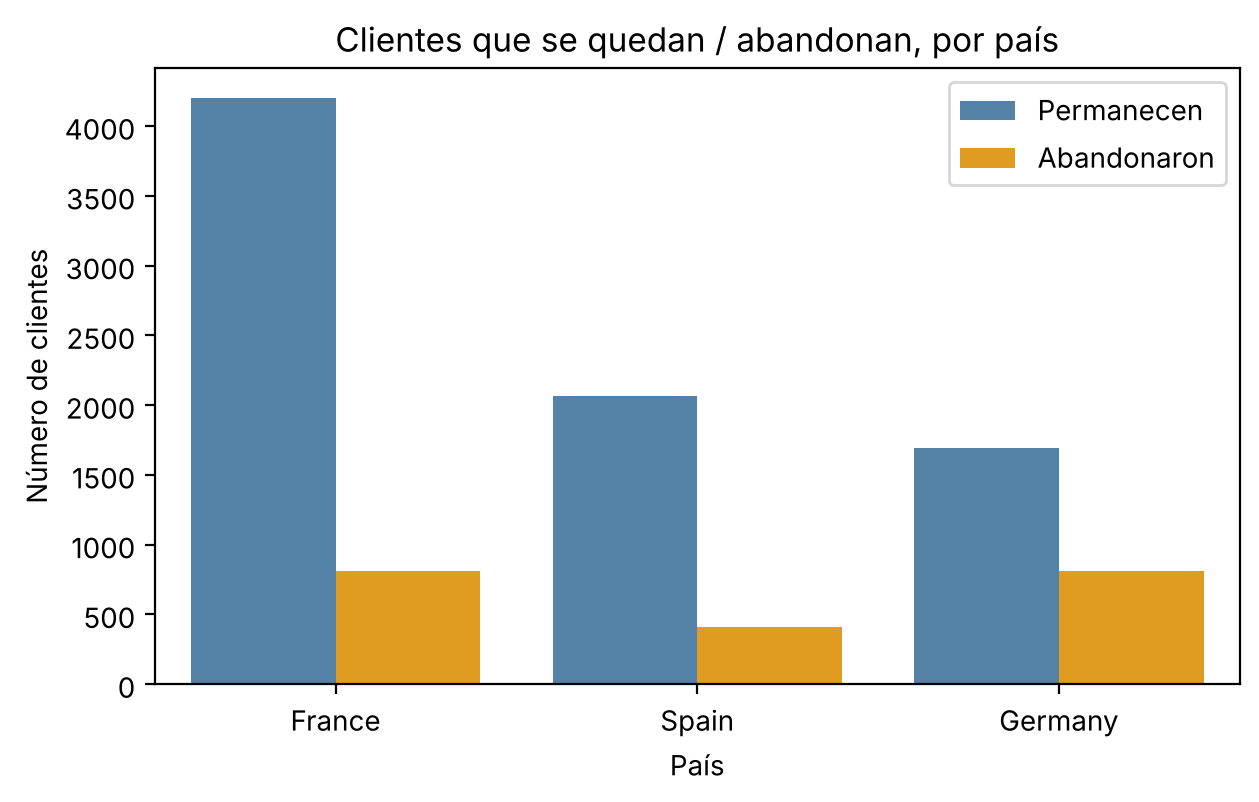

In [6]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Geography", hue="Exited", palette={0: "steelblue", 1: "orange"})
plt.title("Clientes que se quedan / abandonan, por país")
plt.xlabel("País"); plt.ylabel("Número de clientes")
plt.legend(["Permanecen", "Abandonaron"])
plt.show()

**Qué vemos:** Francia tiene el doble de clientes que Alemania, pero los dos países tienen **casi el mismo número de abandonos** (810 y 814). Contar personas no basta: hay que comparar **tasas** (sección 2.6).

### 2.4 Edad de quienes se van y de quienes permanecen
Comparamos **media** y **mediana**. El boxplot permite ver la dispersión y los posibles valores atípicos.

Estadísticas de edad según abandono:
        count   mean  median
Exited                      
0        7963  37.41    36.0
1        2037  44.84    45.0


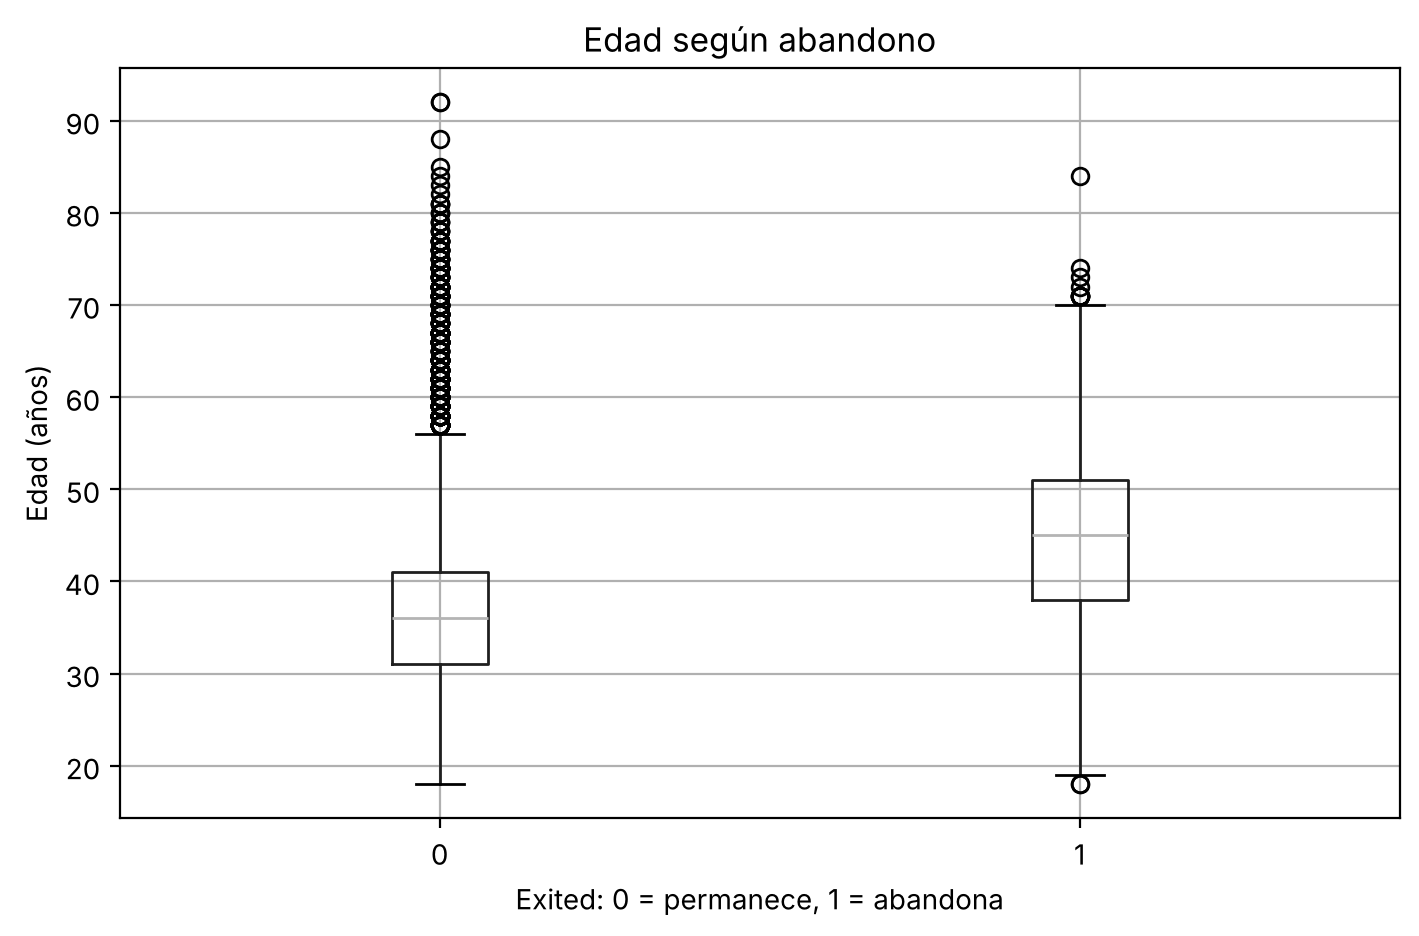

In [7]:
print("Estadísticas de edad según abandono:")
print(df.groupby("Exited")["Age"].agg(["count", "mean", "median"]).round(2))

df.boxplot(column="Age", by="Exited", figsize=(8, 5))
plt.title("Edad según abandono")
plt.suptitle("")
plt.xlabel("Exited: 0 = permanece, 1 = abandona")
plt.ylabel("Edad (años)")
plt.show()

**Qué vemos:**
- Quienes abandonaron son **mayores**: media de 44.8 años contra 37.4 de quienes permanecieron (medianas de 45 y 36).
- La mitad de los clientes que abandonan tiene **45 años o menos** (la mediana).
- Los dos grupos tienen distribuciones diferentes: una misma edad (por ejemplo, 60 años) aparece como atípica entre quienes permanecen, pero no entre quienes abandonan.

### 2.5 Número de clientes por edad (y por país)
Estas gráficas muestran la tendencia completa, edad por edad.

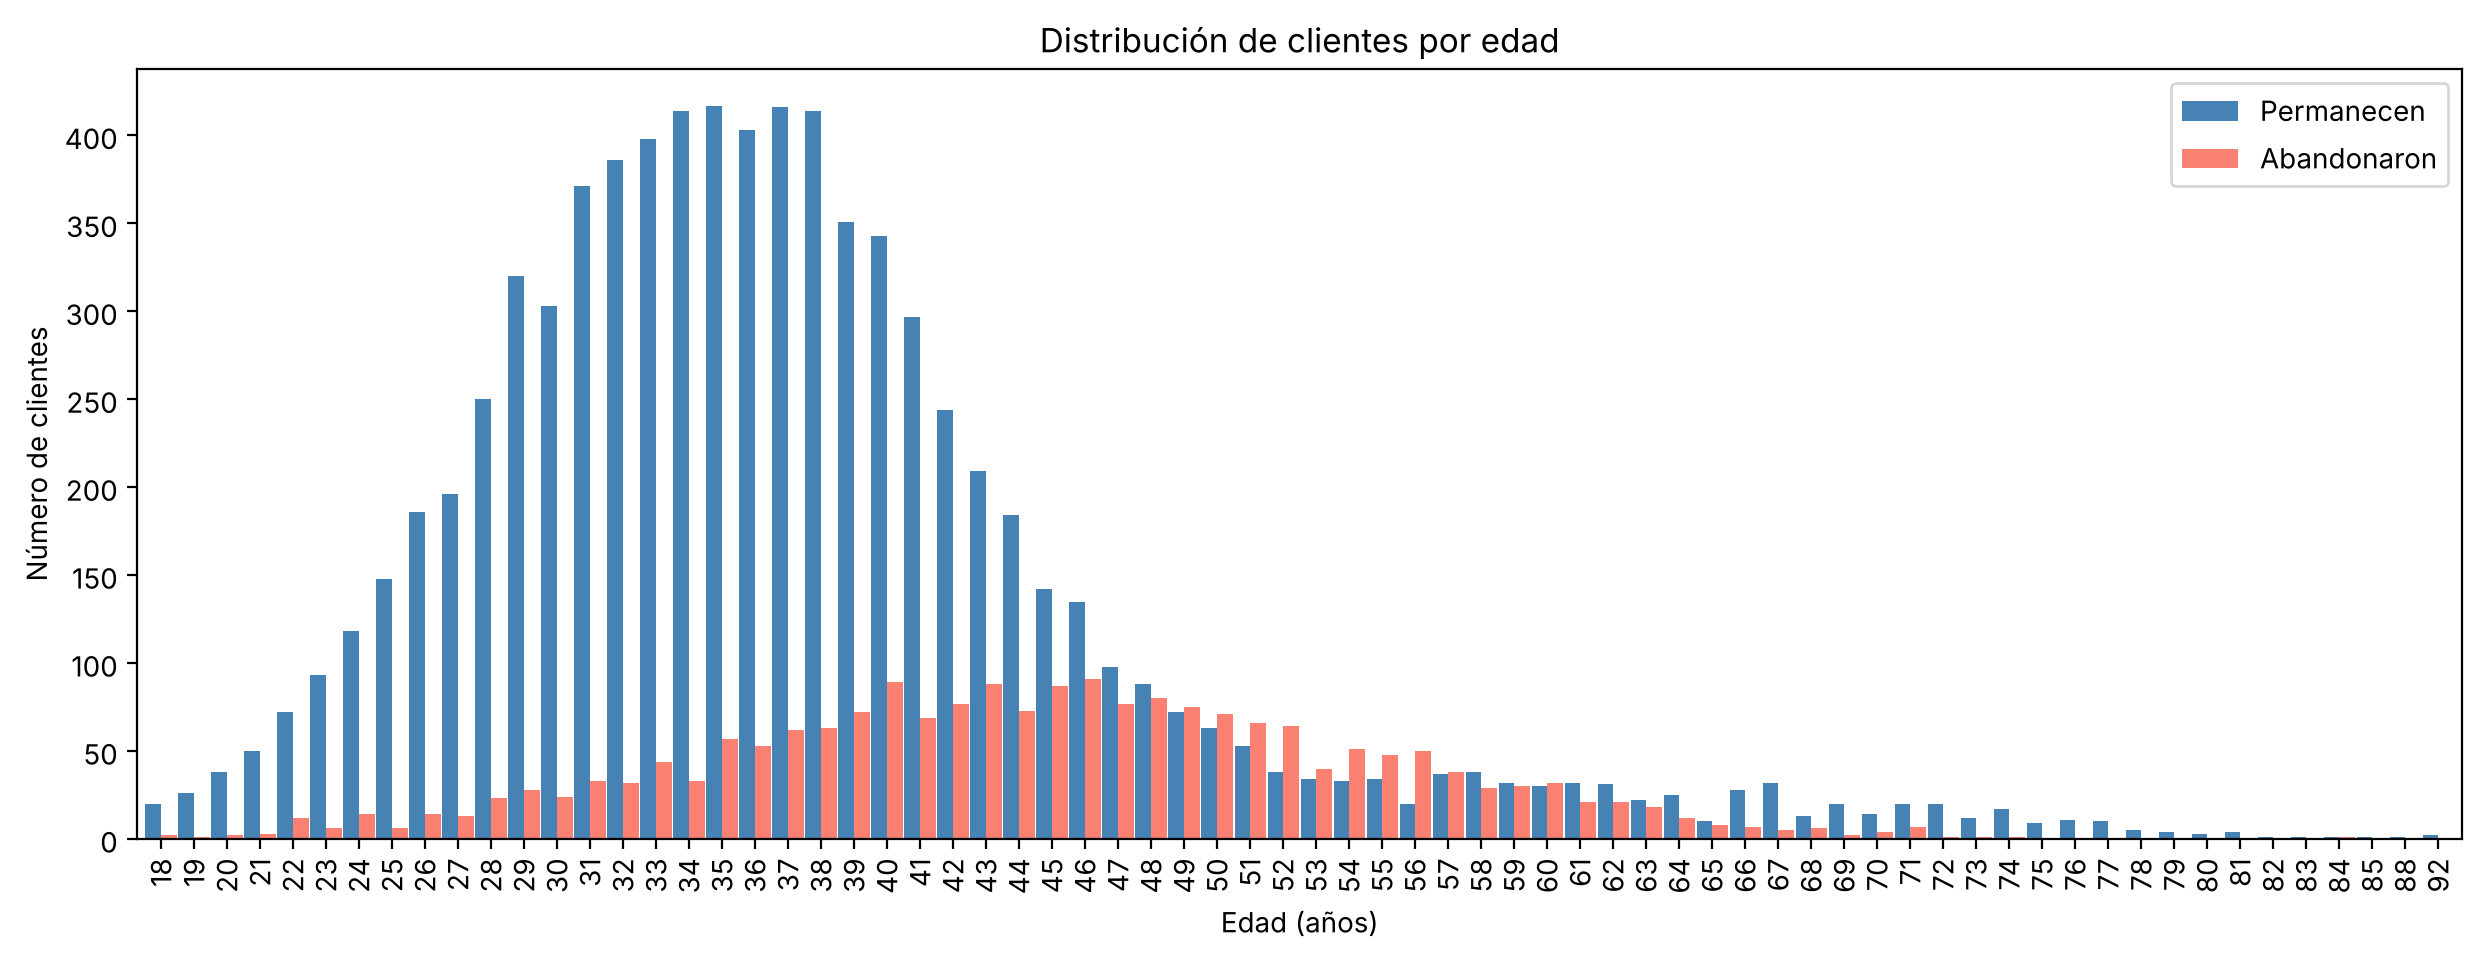

In [8]:
tabla_edades = pd.crosstab(df["Age"], df["Exited"])
tabla_edades.plot(kind="bar", figsize=(15, 5), width=0.95, color=["steelblue", "salmon"])
plt.title("Distribución de clientes por edad")
plt.xlabel("Edad (años)"); plt.ylabel("Número de clientes")
plt.legend(["Permanecen", "Abandonaron"])
plt.show()

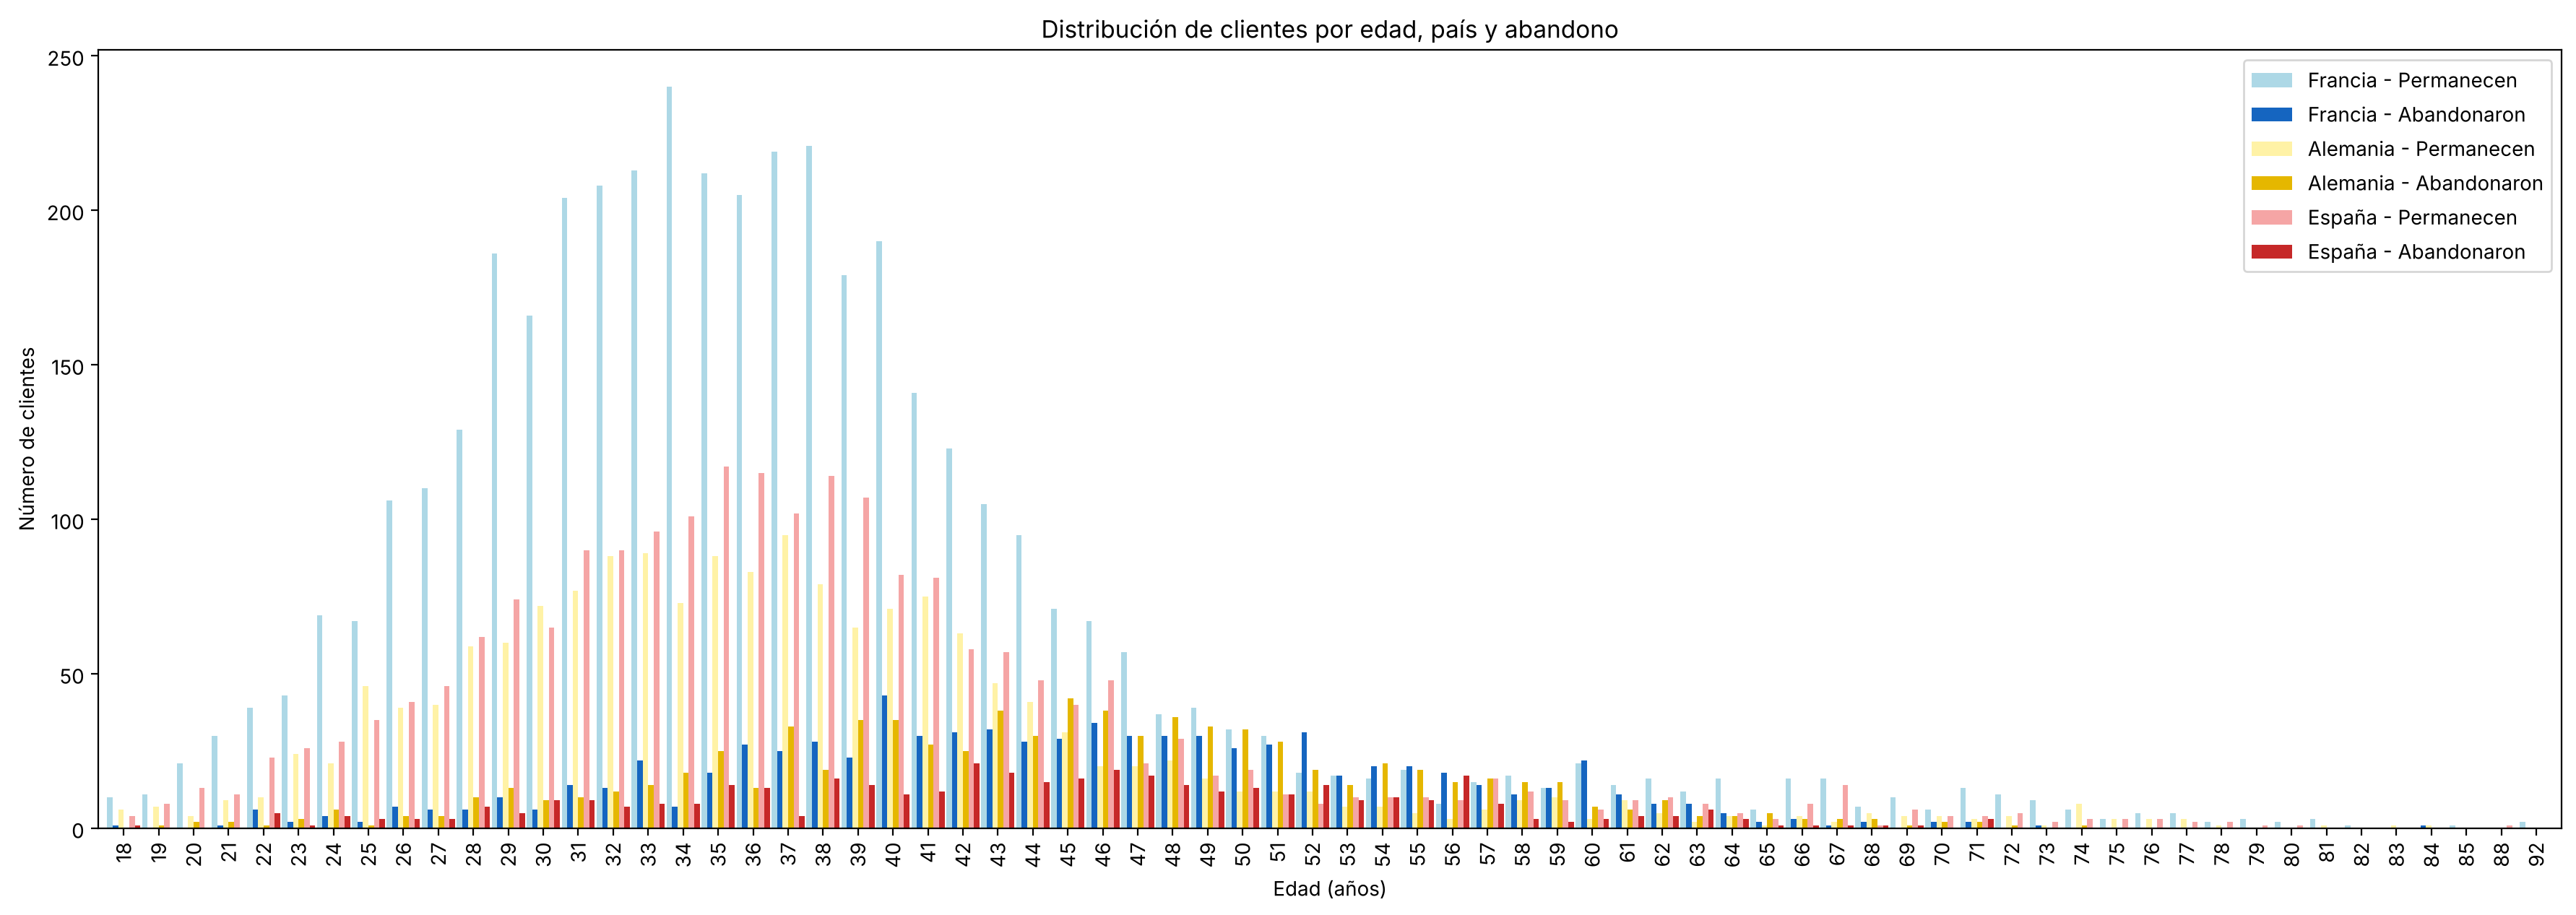

In [9]:
tabla_edades_pais = pd.crosstab(df["Age"], [df["Geography"], df["Exited"]])
tabla_edades_pais.plot(
    kind="bar", figsize=(22, 7), width=0.95,
    color=["#ADD8E6", "#1565C0",   # Francia: permanecen / abandonaron
           "#FFF2A6", "#E5B700",   # Alemania: permanecen / abandonaron
           "#F5A5A5", "#C62828"])  # España: permanecen / abandonaron
plt.title("Distribución de clientes por edad, país y abandono")
plt.xlabel("Edad (años)"); plt.ylabel("Número de clientes")
plt.legend(["Francia - Permanecen", "Francia - Abandonaron", "Alemania - Permanecen",
            "Alemania - Abandonaron", "España - Permanecen", "España - Abandonaron"])
plt.show()

**Qué vemos:** el grupo más grande de clientes tiene entre 30 y 39 años, y casi no abandona. Los abandonos se concentran **entre los 40 y los 60 años**; de los 49 a los 57 años, los que se van **superan** a los que se quedan. El patrón se repite en los tres países, y en Alemania es más marcado.

### 2.6 Tasa de abandono por país, actividad y número de productos
Una tasa representa la **proporción** de abandonos, no el número de personas, así que se pueden comparar grupos de distinto tamaño.

Creamos **una función sencilla**, como en la semana 2, para no repetir el mismo cálculo:
- `count`: número de clientes del grupo.
- `sum`: número de abandonos (porque `Exited` vale 1 cuando abandona).
- `mean`: tasa de abandono del grupo.


Abandono por Geography:
           clientes  abandonos   tasa
Geography                            
France         5014        810  0.162
Germany        2509        814  0.324
Spain          2477        413  0.167

Abandono por IsActiveMember:
                clientes  abandonos   tasa
IsActiveMember                            
0                   4849       1302  0.269
1                   5151        735  0.143

Abandono por NumOfProducts:
               clientes  abandonos   tasa
NumOfProducts                            
1                  5084       1409  0.277
2                  4590        348  0.076
3                   266        220  0.827
4                    60         60  1.000


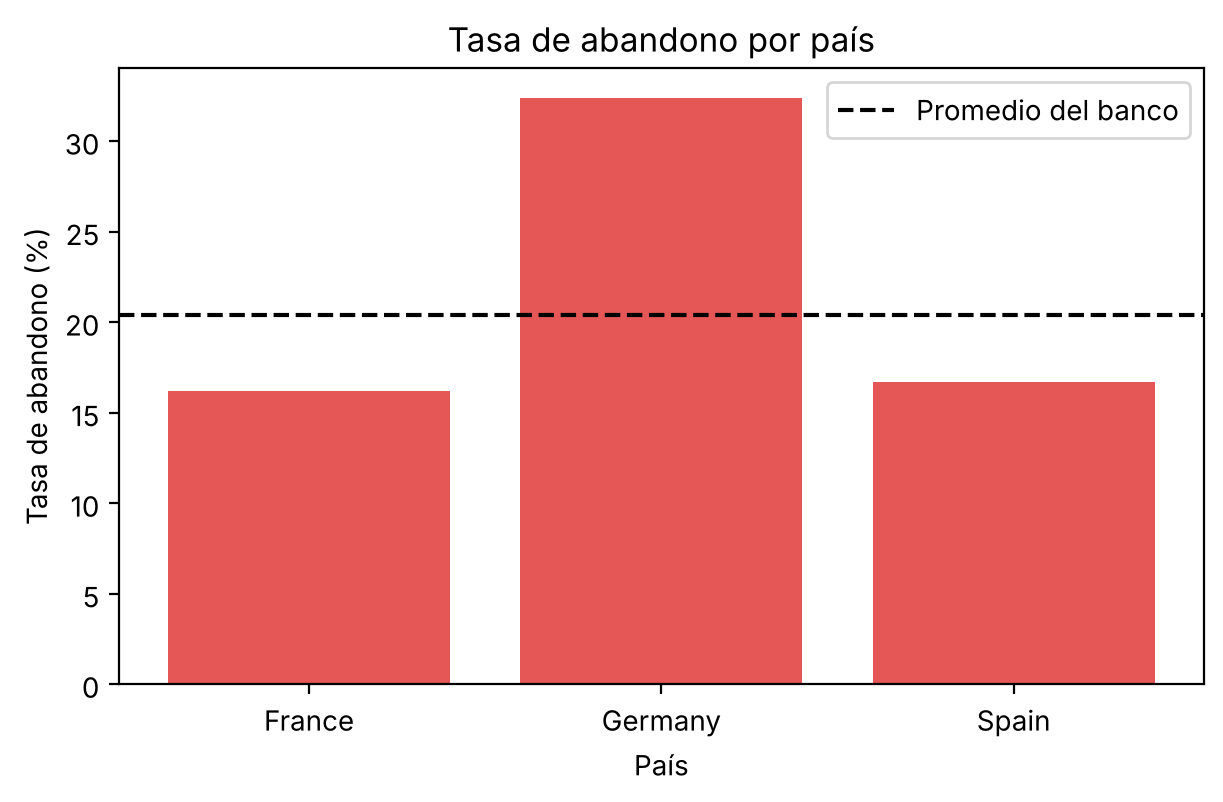

In [10]:
def resumen_abandono(columna):
    # Resume cantidad de clientes, abandonos y tasa por categoría
    return df.groupby(columna)["Exited"].agg(clientes="count", abandonos="sum", tasa="mean").round(3)

for columna in ["Geography", "IsActiveMember", "NumOfProducts"]:
    print(f"\nAbandono por {columna}:")
    print(resumen_abandono(columna))

por_pais = resumen_abandono("Geography")
plt.figure(figsize=(7, 4))
plt.bar(por_pais.index, por_pais["tasa"] * 100, color="#E45756")
plt.axhline(df["Exited"].mean() * 100, color="black", linestyle="--", label="Promedio del banco")
plt.title("Tasa de abandono por país")
plt.xlabel("País"); plt.ylabel("Tasa de abandono (%)")
plt.legend()
plt.show()

**Qué vemos:**
- **País:** Alemania abandona el **32%**, el doble que Francia y España (16% y 17%).
- **Actividad:** los inactivos abandonan el **27%** y los activos el 14%: casi el doble.
- **Número de productos:** con 1 producto abandona el 28%; con 2 **baja** al 8%; con 3 o 4 **sube** a 83% y 100%. La relación sube y baja, no es una recta. Ojo: los grupos de 3 y 4 productos son pequeños (266 y 60 clientes).

### Conclusión de la semana 2
Los perfiles que más abandonan son: **mayores de 40**, de **Alemania**, **inactivos** y con **3 o 4 productos**. Hay un grupo grande de clientes con **saldo 0**.

## 3 · Semana 3: Probabilidad e inferencia
**Pregunta:** las diferencias que vimos, ¿son reales o pueden ser azar?

Estas herramientas cuantifican la incertidumbre y evalúan **asociaciones**, pero no prueban que una variable cause el abandono.

### 3.1 Intervalo de confianza de la tasa de abandono por rango de edad
La tasa de cada grupo es una **proporción**. Con la aproximación normal, el intervalo de confianza al 95% es:

$$\hat{p} \pm 1.96\sqrt{\frac{\hat{p}(1-\hat{p})}{n}}$$

Un grupo con pocos clientes tiene un intervalo más ancho: sabemos su tasa con menos precisión.

In [11]:
df["RangoEdad"] = pd.cut(df["Age"], bins=[17, 29, 39, 49, 59, 69, 120],
                         labels=["18-29", "30-39", "40-49", "50-59", "60-69", "70+"])

por_edad = df.groupby("RangoEdad", observed=True)["Exited"].agg(clientes="count", abandonos="sum", tasa="mean")
margen = 1.96 * np.sqrt(por_edad["tasa"] * (1 - por_edad["tasa"]) / por_edad["clientes"])
por_edad["Tasa (%)"] = por_edad["tasa"] * 100
por_edad["IC inferior (%)"] = (por_edad["tasa"] - margen) * 100
por_edad["IC superior (%)"] = (por_edad["tasa"] + margen) * 100

print(por_edad[["clientes", "abandonos", "Tasa (%)", "IC inferior (%)", "IC superior (%)"]].round(2))
print("\nRango de mayor abandono:", por_edad["tasa"].idxmax())

           clientes  abandonos  Tasa (%)  IC inferior (%)  IC superior (%)
RangoEdad                                                                 
18-29          1641        124      7.56             6.28             8.84
30-39          4346        473     10.88             9.96            11.81
40-49          2618        806     30.79            29.02            32.56
50-59           869        487     56.04            52.74            59.34
60-69           375        132     35.20            30.37            40.03
70+             151         15      9.93             5.16            14.70

Rango de mayor abandono: 50-59


**Qué vemos:**
- El rango de **50 a 59 años** es el de mayor abandono: **56%**, con un intervalo de 52.7% a 59.3%.
- Ese intervalo **no se cruza** con el de ningún otro rango: la diferencia no se explica por azar.
- El rango de 70 años o más tiene un intervalo muy ancho (5% a 15%) porque solo hay 151 clientes.
- El abandono sube con la edad hasta los 50-59 y **vuelve a bajar** después de los 60.

### 3.2 Prueba chi-cuadrada: país y abandono
- **H₀:** país y abandono son independientes.
- **H₁:** existe asociación entre país y abandono.
- **Criterio:** si el valor p es menor a 0.05, rechazamos H₀ (bajo los supuestos de la prueba).

Usamos `pd.crosstab` y `stats.chi2_contingency`, como en la semana 3.

In [12]:
tabla = pd.crosstab(df["Geography"], df["Exited"])
chi2, p_valor, gl, esperados = stats.chi2_contingency(tabla)
print("Tabla de frecuencias:")
print(tabla)
print(f"\nChi-cuadrada = {chi2:.2f} | grados de libertad = {gl} | valor p = {p_valor:.2e}")
if p_valor < 0.05:
    print("Conclusión: hay evidencia de asociación entre país y abandono.")
else:
    print("Conclusión: no hay evidencia suficiente de asociación entre país y abandono.")

Tabla de frecuencias:
Exited        0    1
Geography           
France     4204  810
Germany    1695  814
Spain      2064  413

Chi-cuadrada = 301.26 | grados de libertad = 2 | valor p = 3.83e-66
Conclusión: hay evidencia de asociación entre país y abandono.


**Qué vemos:** chi-cuadrada de 301 y valor p prácticamente 0 (3.8 × 10⁻⁶⁶): **rechazamos H₀**. El abandono está asociado con el país; la diferencia de Alemania no es casualidad.

### Conclusión de la semana 3
Las dos diferencias más grandes (la edad de 50-59 años y Alemania) son **estadísticamente significativas**: no se explican por azar. Eso no dice **por qué** se van esos clientes.

## 4 · Conclusiones

**Respuesta a la pregunta: ¿qué perfiles presentan mayor tasa de abandono?**
1. **Abandono global:** 2,037 de 10,000 clientes (**20.4%**).
2. **País:** Alemania abandona el **32%**, el doble que Francia y España (16% y 17%). La prueba chi-cuadrada confirma la asociación.
3. **Edad:** quienes abandonan son mayores (44.8 contra 37.4 años en promedio). El rango de **50-59 años** abandona el **56%**, y su intervalo de confianza no se cruza con el de ningún otro rango.
4. **Actividad:** los inactivos abandonan casi el doble que los activos (27% contra 14%).
5. **Número de productos:** 2 productos es el punto más bajo (8%); con 3 o 4 casi todos se van, aunque son grupos pequeños.

**Qué sigue:** estos perfiles son el punto de partida. En las semanas 7 a 9 los usamos para **predecir** quién se va (regresión, clasificación y clustering).

**Límites**
- Son patrones **descriptivos**: muestran asociación, no causa. No sabemos por qué se van los clientes de Alemania o de 50 años.
- No debemos concluir mucho sobre grupos muy pequeños: por ejemplo, el grupo con 4 productos tiene solo 60 clientes, y el de 70 años o más, 151.
- No se sabe de qué banco ni de qué años son los datos.